# BQ08 — Monthly revenue liên quan thế nào đến risk và value?

## Câu hỏi nói đơn giản

Khách hàng có doanh thu tháng cao có nhất thiết dễ rời bỏ hơn không? Nếu không, nhóm nào có **xác suất churn cao** và nhóm nào tạo ra **mức doanh thu đang phơi nhiễm trước churn lớn**?

- **Risk:** tỷ lệ khách hàng churn.
- **Value proxy:** `MonthlyRevenue` — chỉ là doanh thu tháng quan sát được, **không phải** CLV, lợi nhuận hay biên lợi nhuận.
- **Revenue-at-risk proxy:** tổng `MonthlyRevenue` của những khách hàng đã churn trong snapshot. Đây là chỉ báo phơi nhiễm, không phải tổn thất tài chính đã xác nhận.

**Feature sử dụng:** `MonthlyRevenue`, `Churn`.

**Đầu ra quyết định:** tạo chiều value cho bước ưu tiên giữ chân ở BQ18, đồng thời tránh nhầm nhóm risk cao với nhóm có tác động doanh thu lớn.

**Đã xác minh:** 9/9 code cell chạy thành công trên dữ liệu hiện có ngày 28/10/2026; notebook được lưu sạch, không nhúng output chạy thử.

In [1]:
BQ08_NOTEBOOK_VERSION = 'BQ08_RISK_VALUE_V1_2026-10-28'
print(f'Đang chạy: {BQ08_NOTEBOOK_VERSION}')

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import display
from scipy.stats import chi2_contingency, norm

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.style.use('seaborn-v0_8-whitegrid')

ALPHA = 0.05
N_TIERS = 5
TIER_ORDER = ['Q1 — Thấp nhất', 'Q2 — Thấp', 'Q3 — Trung bình', 'Q4 — Cao', 'Q5 — Cao nhất']
COLORS = ['#90BE6D', '#43AA8B', '#4D908E', '#577590', '#F94144']

Đang chạy: BQ08_RISK_VALUE_V1_2026-10-28


## 1. Đọc dữ liệu và kiểm tra chất lượng

Giá trị âm được báo riêng và không dùng để tạo value tier vì doanh thu tháng âm có thể là điều chỉnh hóa đơn hoặc lỗi dữ liệu; cần nghiệp vụ xác nhận trước khi diễn giải.

In [2]:
DATA_CANDIDATES = [
    Path('../data/cell2cell_complete_cases.csv'),
    Path('data/cell2cell_complete_cases.csv'),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy data/cell2cell_complete_cases.csv')

raw = pd.read_csv(DATA_PATH, usecols=['Churn', 'MonthlyRevenue'])

def normalize_churn(series):
    values = series.astype('string').str.strip().str.lower()
    mapping = {
        'yes': 1, 'y': 1, 'true': 1, '1': 1, '1.0': 1,
        'no': 0, 'n': 0, 'false': 0, '0': 0, '0.0': 0,
    }
    return values.map(mapping).astype('Float64')

work = raw.copy()
work['Churn_bin'] = normalize_churn(work['Churn'])
work['MonthlyRevenue'] = pd.to_numeric(work['MonthlyRevenue'], errors='coerce')

valid_mask = (
    work['Churn_bin'].notna()
    & work['MonthlyRevenue'].notna()
    & work['MonthlyRevenue'].ge(0)
)
analysis = work.loc[valid_mask, ['Churn_bin', 'MonthlyRevenue']].copy()
analysis['Churn_bin'] = analysis['Churn_bin'].astype(int)

qa = pd.DataFrame({
    'Chỉ tiêu': [
        'Tổng số khách hàng',
        'Churn thiếu/không hợp lệ',
        'MonthlyRevenue thiếu/không hợp lệ',
        'MonthlyRevenue âm — loại khỏi BQ08',
        'MonthlyRevenue bằng 0 — vẫn giữ',
        'Cohort hợp lệ BQ08',
    ],
    'Số khách hàng': [
        len(work),
        work['Churn_bin'].isna().sum(),
        work['MonthlyRevenue'].isna().sum(),
        work['MonthlyRevenue'].lt(0).sum(),
        work['MonthlyRevenue'].eq(0).sum(),
        len(analysis),
    ],
})
display(qa)
display(analysis['MonthlyRevenue'].describe(percentiles=[.01, .25, .5, .75, .95, .99]).to_frame().T)

,Chỉ tiêu,Số khách hàng
0,Tổng số khách hàng,49752
1,Churn thiếu/không hợp lệ,0
2,MonthlyRevenue thiếu/không hợp lệ,0
3,MonthlyRevenue âm — loại khỏi BQ08,2
4,MonthlyRevenue bằng 0 — vẫn giữ,4
5,Cohort hợp lệ BQ08,49750


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
MonthlyRevenue,"49,750.0000",58.7200,44.3162,0.0000,10.0000,33.6100,48.3800,70.9100,134.4900,224.6557,"1,223.3800"


## 2. Nhìn phân phối trước khi chia value tier

Biểu đồ tập trung đến P99 để phần đuôi cực lớn không ép phần lớn dữ liệu vào một góc. Giá trị lớn hơn P99 vẫn được giữ trong phân tích chính và được kiểm tra độ nhạy ở phần sau.

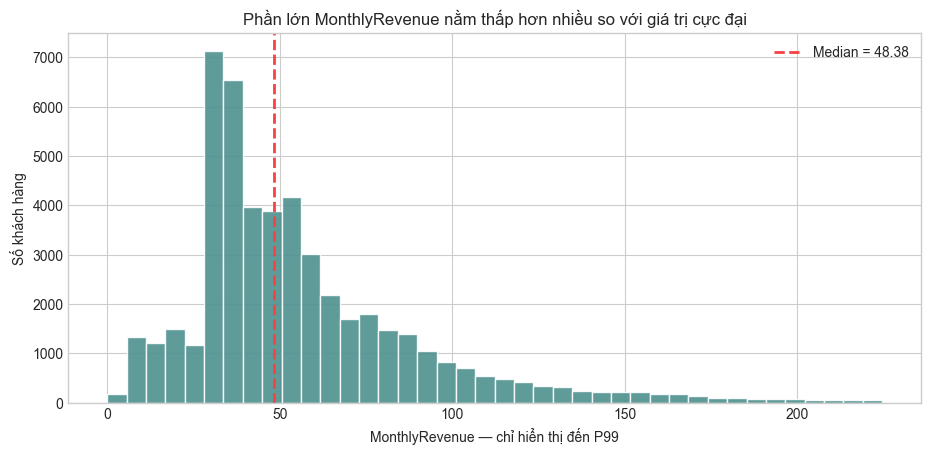

,Median,P99,Max,Max / P99,Số khách hàng trên P99
0,48.3800,224.6557,"1,223.3800",5.4456,498


In [3]:
p50 = analysis['MonthlyRevenue'].median()
p99 = analysis['MonthlyRevenue'].quantile(.99)
maximum = analysis['MonthlyRevenue'].max()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.hist(
    analysis.loc[analysis['MonthlyRevenue'].le(p99), 'MonthlyRevenue'],
    bins=40, color='#4D908E', edgecolor='white', alpha=.9
)
ax.axvline(p50, color='#F94144', linestyle='--', linewidth=2, label=f'Median = {p50:,.2f}')
ax.set(
    title='Phần lớn MonthlyRevenue nằm thấp hơn nhiều so với giá trị cực đại',
    xlabel='MonthlyRevenue — chỉ hiển thị đến P99',
    ylabel='Số khách hàng',
)
ax.legend()
plt.show()

tail_summary = pd.DataFrame([{
    'Median': p50,
    'P99': p99,
    'Max': maximum,
    'Max / P99': maximum / p99,
    'Số khách hàng trên P99': analysis['MonthlyRevenue'].gt(p99).sum(),
}])
display(tail_summary)

## 3. Tạo 5 value tier có số khách hàng gần bằng nhau

Ngưỡng được lấy từ các phân vị 20%, 40%, 60% và 80% của chính cohort BQ08. Cách này tạo nhóm đủ lớn để so sánh và cho phép ghi lại chính xác các biên; đây là phân tầng value, không phải bằng chứng rằng tồn tại điểm gãy hành vi tự nhiên.

In [4]:
tier_codes, tier_edges = pd.qcut(
    analysis['MonthlyRevenue'],
    q=N_TIERS,
    labels=False,
    retbins=True,
    duplicates='drop',
)
if len(tier_edges) - 1 != N_TIERS:
    raise ValueError('Không tạo đủ 5 tier vì có quá nhiều giá trị trùng tại biên phân vị')

analysis['ValueTier'] = pd.Categorical(
    pd.Series(tier_codes, index=analysis.index).map(dict(enumerate(TIER_ORDER))),
    categories=TIER_ORDER,
    ordered=True,
)

boundary_rows = []
for index, tier in enumerate(TIER_ORDER):
    left_symbol = '[' if index == 0 else '('
    boundary_rows.append({
        'ValueTier': tier,
        'Khoảng MonthlyRevenue': f'{left_symbol}{tier_edges[index]:,.2f}; {tier_edges[index + 1]:,.2f}]',
        'Biên dưới': tier_edges[index],
        'Biên trên': tier_edges[index + 1],
    })
tier_boundaries = pd.DataFrame(boundary_rows)
display(tier_boundaries)

,ValueTier,Khoảng MonthlyRevenue,Biên dưới,Biên trên
0,Q1 — Thấp nhất,[0.00; 31.11],0.0000,31.1100
1,Q2 — Thấp,(31.11; 40.25],31.1100,40.2500
2,Q3 — Trung bình,(40.25; 54.28],40.2500,54.2800
3,Q4 — Cao,(54.28; 78.92],54.2800,78.9200
4,Q5 — Cao nhất,"(78.92; 1,223.38]",78.9200,"1,223.3800"


## 4. Bảng bằng chứng: tách risk khỏi value

`ChurnRate` trả lời **ai dễ churn hơn**. `RevenueAtRiskProxy` trả lời **doanh thu tháng hiện diện trong nhóm đã churn tập trung ở đâu**. Hai cột này không nhất thiết cùng xếp hạng.

In [5]:
def wilson_interval(successes, total, alpha=ALPHA):
    z = norm.ppf(1 - alpha / 2)
    p = successes / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    return center - half_width, center + half_width

analysis['RevenueAtRiskProxy'] = analysis['MonthlyRevenue'] * analysis['Churn_bin']
overall_churn = analysis['Churn_bin'].mean()

tier_summary = (
    analysis.groupby('ValueTier', observed=True)
        .agg(
            Customers=('Churn_bin', 'size'),
            Churners=('Churn_bin', 'sum'),
            ChurnRate=('Churn_bin', 'mean'),
            MedianRevenue=('MonthlyRevenue', 'median'),
            Q1Revenue=('MonthlyRevenue', lambda x: x.quantile(.25)),
            Q3Revenue=('MonthlyRevenue', lambda x: x.quantile(.75)),
            TotalMonthlyRevenue=('MonthlyRevenue', 'sum'),
            RevenueAtRiskProxy=('RevenueAtRiskProxy', 'sum'),
        )
        .reset_index()
)

intervals = tier_summary.apply(
    lambda row: wilson_interval(int(row['Churners']), int(row['Customers'])), axis=1
)
tier_summary['CI_low'] = [interval[0] for interval in intervals]
tier_summary['CI_high'] = [interval[1] for interval in intervals]
tier_summary['ChurnLift'] = tier_summary['ChurnRate'] / overall_churn
tier_summary['CustomerShare'] = tier_summary['Customers'] / tier_summary['Customers'].sum()
tier_summary['RevenueShare'] = tier_summary['TotalMonthlyRevenue'] / tier_summary['TotalMonthlyRevenue'].sum()
tier_summary['RevenueAtRiskShare'] = (
    tier_summary['RevenueAtRiskProxy'] / tier_summary['RevenueAtRiskProxy'].sum()
)

display(tier_summary[[
    'ValueTier', 'Customers', 'Churners', 'ChurnRate', 'CI_low', 'CI_high',
    'ChurnLift', 'MedianRevenue', 'Q1Revenue', 'Q3Revenue',
    'RevenueAtRiskProxy', 'RevenueAtRiskShare'
]])

,ValueTier,Customers,Churners,ChurnRate,CI_low,CI_high,ChurnLift,MedianRevenue,Q1Revenue,Q3Revenue,RevenueAtRiskProxy,RevenueAtRiskShare
0,Q1 — Thấp nhất,9954,3102,0.3116,0.3026,0.3208,1.0884,26.1250,15.7300,30.0700,"69,966.7800",0.0849
1,Q2 — Thấp,9947,2813,0.2828,0.2740,0.2917,0.9877,35.2800,33.6200,37.4400,"99,628.5400",0.1208
2,Q3 — Trung bình,9953,2763,0.2776,0.2689,0.2865,0.9695,48.3800,43.8800,50.9700,"132,175.5500",0.1603
3,Q4 — Cao,9950,2806,0.2820,0.2733,0.2909,0.9849,63.5200,58.6200,70.9300,"181,383.4500",0.2200
4,Q5 — Cao nhất,9946,2761,0.2776,0.2689,0.2865,0.9695,103.4000,88.4750,134.4975,"341,250.0900",0.4139


## 5. C08 — Ba biểu đồ, ba câu hỏi

1. **Volume:** mỗi tier có đủ khách hàng để so sánh không?
2. **Risk:** tier nào có churn rate cao hơn?
3. **Value exposure:** doanh thu tháng của khách hàng churn tập trung ở tier nào?

Không dùng dual axis để tránh đánh đồng ba thước đo khác đơn vị.

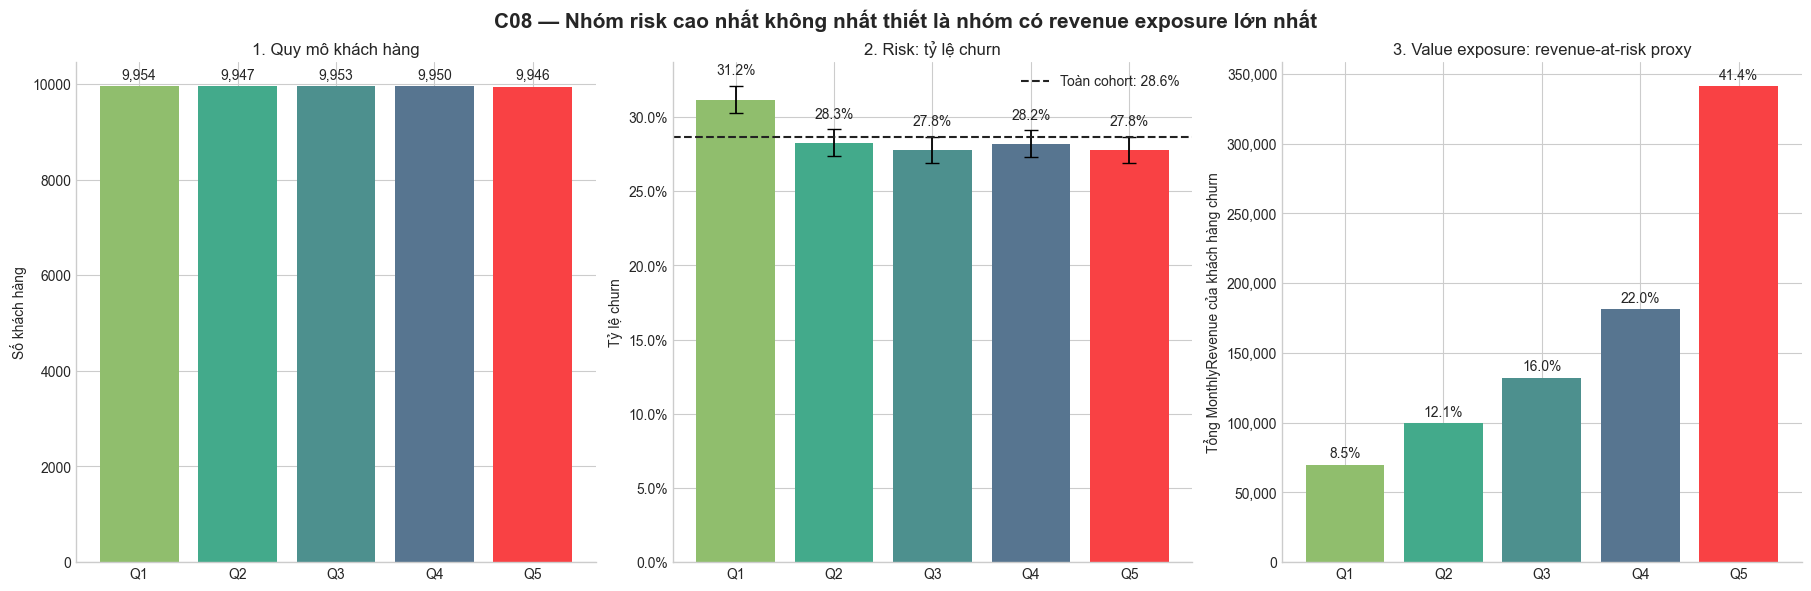

In [6]:
x = np.arange(len(tier_summary))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), constrained_layout=True)

bars = axes[0].bar(x, tier_summary['Customers'], color=COLORS)
axes[0].set(title='1. Quy mô khách hàng', ylabel='Số khách hàng')
axes[0].bar_label(bars, labels=[f'{value:,.0f}' for value in tier_summary['Customers']], padding=3)

yerr = np.vstack([
    tier_summary['ChurnRate'] - tier_summary['CI_low'],
    tier_summary['CI_high'] - tier_summary['ChurnRate'],
])
bars = axes[1].bar(
    x, tier_summary['ChurnRate'], yerr=yerr, capsize=5, color=COLORS,
    error_kw={'elinewidth': 1.3}
)
axes[1].axhline(overall_churn, color='#222222', linestyle='--', linewidth=1.5,
                label=f'Toàn cohort: {overall_churn:.1%}')
axes[1].set(title='2. Risk: tỷ lệ churn', ylabel='Tỷ lệ churn')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].bar_label(bars, labels=[f'{value:.1%}' for value in tier_summary['ChurnRate']], padding=6)
axes[1].legend()

bars = axes[2].bar(x, tier_summary['RevenueAtRiskProxy'], color=COLORS)
axes[2].set(
    title='3. Value exposure: revenue-at-risk proxy',
    ylabel='Tổng MonthlyRevenue của khách hàng churn',
)
axes[2].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
axes[2].bar_label(
    bars,
    labels=[f'{share:.1%}' for share in tier_summary['RevenueAtRiskShare']],
    padding=3,
)

for ax in axes:
    ax.set_xticks(x, ['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle(
    'C08 — Nhóm risk cao nhất không nhất thiết là nhóm có revenue exposure lớn nhất',
    fontsize=15, fontweight='bold'
)
plt.show()

## 6. Kiểm định: khác biệt có lớn hay chỉ có ý nghĩa thống kê?

Chi-square trả lời churn có khác giữa các tier hay không. Cramér's V đo **độ lớn liên hệ**; với mẫu lớn, p-value có thể rất nhỏ dù hiệu ứng thực tế yếu.

In [7]:
contingency = pd.crosstab(analysis['ValueTier'], analysis['Churn_bin'])
chi2_value, chi2_p, chi2_df, expected = chi2_contingency(contingency)
n = contingency.to_numpy().sum()
cramers_v = np.sqrt(chi2_value / (n * min(contingency.shape[0] - 1, contingency.shape[1] - 1)))

if cramers_v < .10:
    effect_label = 'rất yếu'
elif cramers_v < .30:
    effect_label = 'yếu đến vừa'
else:
    effect_label = 'mạnh'

test_result = pd.DataFrame([{
    'Chi-square': chi2_value,
    'df': chi2_df,
    'p-value': chi2_p,
    "Cramér's V": cramers_v,
    'Độ lớn liên hệ': effect_label,
}])
display(test_result)
print(
    f'Kết luận thống kê: churn khác giữa các tier (p={chi2_p:.3g}), '
    f'nhưng độ lớn liên hệ {effect_label} (V={cramers_v:.3f}).'
)

,Chi-square,df,p-value,Cramér's V,Độ lớn liên hệ
0,40.1224,4,0.0000,0.0284,rất yếu


Kết luận thống kê: churn khác giữa các tier (p=4.08e-08), nhưng độ lớn liên hệ rất yếu (V=0.028).


## 7. Kiểm tra phần đuôi có chi phối revenue-at-risk không

Giới hạn `MonthlyRevenue` tại P99 rồi tính lại tỷ trọng revenue-at-risk. Nếu thứ hạng và tỷ trọng chỉ thay đổi ít, insight không bị một vài giá trị cực lớn quyết định.

In [8]:
winsor_cap = analysis['MonthlyRevenue'].quantile(.99)
analysis['MonthlyRevenue_P99'] = analysis['MonthlyRevenue'].clip(upper=winsor_cap)
analysis['RevenueAtRisk_P99'] = analysis['MonthlyRevenue_P99'] * analysis['Churn_bin']

sensitivity = (
    analysis.groupby('ValueTier', observed=True)
        .agg(
            Original=('RevenueAtRiskProxy', 'sum'),
            WinsorizedP99=('RevenueAtRisk_P99', 'sum'),
        )
        .reset_index()
)
sensitivity['OriginalShare'] = sensitivity['Original'] / sensitivity['Original'].sum()
sensitivity['WinsorizedShare'] = sensitivity['WinsorizedP99'] / sensitivity['WinsorizedP99'].sum()
sensitivity['ShareChange_pp'] = (sensitivity['WinsorizedShare'] - sensitivity['OriginalShare']) * 100

largest_original = sensitivity.loc[sensitivity['OriginalShare'].idxmax(), 'ValueTier']
largest_winsor = sensitivity.loc[sensitivity['WinsorizedShare'].idxmax(), 'ValueTier']
max_change_pp = sensitivity['ShareChange_pp'].abs().max()
display(sensitivity)
print(f'Ngưỡng P99: {winsor_cap:,.2f}')
print(f'Tier exposure lớn nhất trước/sau winsor: {largest_original} / {largest_winsor}')
print(f'Thay đổi tỷ trọng lớn nhất: {max_change_pp:.2f} điểm %')

,ValueTier,Original,WinsorizedP99,OriginalShare,WinsorizedShare,ShareChange_pp
0,Q1 — Thấp nhất,"69,966.7800","69,966.7800",0.0849,0.0861,0.1192
1,Q2 — Thấp,"99,628.5400","99,628.5400",0.1208,0.1225,0.1697
2,Q3 — Trung bình,"132,175.5500","132,175.5500",0.1603,0.1626,0.2251
3,Q4 — Cao,"181,383.4500","181,383.4500",0.2200,0.2231,0.3090
4,Q5 — Cao nhất,"341,250.0900","329,833.2779",0.4139,0.4057,-0.8230


Ngưỡng P99: 224.66
Tier exposure lớn nhất trước/sau winsor: Q5 — Cao nhất / Q5 — Cao nhất
Thay đổi tỷ trọng lớn nhất: 0.82 điểm %


## 8. Kết luận tự động và hàm ý giữ chân

Phần này buộc notebook trả lời thẳng ba câu: nhóm nào risk cao nhất, nhóm nào exposure lớn nhất và `MonthlyRevenue` nên đóng vai trò gì trong pipeline.

In [9]:
highest_risk = tier_summary.loc[tier_summary['ChurnRate'].idxmax()]
highest_exposure = tier_summary.loc[tier_summary['RevenueAtRiskShare'].idxmax()]
same_tier = highest_risk['ValueTier'] == highest_exposure['ValueTier']

if cramers_v < .10:
    revenue_role = (
        'Giữ MonthlyRevenue làm VALUE PROXY cho ưu tiên nguồn lực; '
        'không gọi đây là churn driver mạnh và không dùng một mình để quyết định ưu đãi.'
    )
else:
    revenue_role = (
        'Giữ MonthlyRevenue cho cả phân tầng risk và value, nhưng vẫn cần kiểm soát '
        'các feature khác trước khi thiết kế chính sách.'
    )

decision_summary = pd.DataFrame([
    {
        'Câu hỏi': 'Tier có churn rate cao nhất',
        'Kết quả': highest_risk['ValueTier'],
        'Số liệu chính': f"{highest_risk['ChurnRate']:.1%}; lift {highest_risk['ChurnLift']:.2f}x",
    },
    {
        'Câu hỏi': 'Tier có revenue-at-risk proxy lớn nhất',
        'Kết quả': highest_exposure['ValueTier'],
        'Số liệu chính': f"{highest_exposure['RevenueAtRiskShare']:.1%} tổng exposure",
    },
    {
        'Câu hỏi': 'Risk và value có cùng một tier không?',
        'Kết quả': 'Có' if same_tier else 'Không',
        'Số liệu chính': 'Phải tách hai chiều khi ưu tiên khách hàng',
    },
    {
        'Câu hỏi': 'Vai trò của MonthlyRevenue',
        'Kết quả': 'Value proxy' if cramers_v < .10 else 'Risk + value signal',
        'Số liệu chính': f"Cramér's V = {cramers_v:.3f} ({effect_label})",
    },
])
display(decision_summary)
print(revenue_role)
print(
    '\nHàm ý chính sách:\n'
    '- Nhóm risk cao nhưng value thấp: ưu tiên can thiệp chi phí thấp, có thể mở rộng.\n'
    '- Nhóm value cao: theo dõi chặt và kết hợp xác suất churn từ mô hình trước khi liên hệ.\n'
    '- Không cấp ưu đãi đắt tiền chỉ vì MonthlyRevenue cao hoặc chỉ vì một tier có churn rate cao.'
)

,Câu hỏi,Kết quả,Số liệu chính
0,Tier có churn rate cao nhất,Q1 — Thấp nhất,31.2%; lift 1.09x
1,Tier có revenue-at-risk proxy lớn nhất,Q5 — Cao nhất,41.4% tổng exposure
2,Risk và value có cùng một tier không?,Không,Phải tách hai chiều khi ưu tiên khách hàng
3,Vai trò của MonthlyRevenue,Value proxy,Cramér's V = 0.028 (rất yếu)


Giữ MonthlyRevenue làm VALUE PROXY cho ưu tiên nguồn lực; không gọi đây là churn driver mạnh và không dùng một mình để quyết định ưu đãi.

Hàm ý chính sách:
- Nhóm risk cao nhưng value thấp: ưu tiên can thiệp chi phí thấp, có thể mở rộng.
- Nhóm value cao: theo dõi chặt và kết hợp xác suất churn từ mô hình trước khi liên hệ.
- Không cấp ưu đãi đắt tiền chỉ vì MonthlyRevenue cao hoặc chỉ vì một tier có churn rate cao.


## 9. Câu kết cho storytelling

> **BQ08 không cố chứng minh khách hàng doanh thu cao dễ churn hơn. BQ08 chứng minh rằng “khả năng rời bỏ” và “giá trị doanh thu đang phơi nhiễm” là hai chiều khác nhau. MonthlyRevenue vì vậy được giữ làm value proxy để kết hợp với churn probability ở BQ18, không được gọi là CLV, lợi nhuận hay nguyên nhân gây churn.**